# Data Import and Cleaning

## Import Dataset

In [15]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set plot fonts
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# Import and show dataset
df = pd.read_csv("D:/RFM-online_retail_II/data/raw_data/online_retail_II.csv")
print(df.shape)
df.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## Data Cleaning
- We need to perform user segmentation using RFM, so rows where `Customer ID IS NULL` are removed.
- Records where `Invoice` starts with the letter C represent cancelled orders and should therefore be excluded.
- Filter outliers: dirty data with `Quantity <= 0` and `UnitPrice <= 0` (free giveaways and refund records).
- Calculate each line's `amount = quantity * price`.
- Convert `InvoiceDate` to datetime type for time analysis.

In [16]:
# Make a copy
rfm_df = df.copy()

# 1. Drop rows without CustomerID
rfm_df = rfm_df.dropna(subset=["Customer ID"])

# 2. Remove cancelled orders starting with 'C'
rfm_df = rfm_df[~rfm_df["Invoice"].astype(str).str.startswith("C")]

# 3. Keep only positive quantity and price
rfm_df = rfm_df[(rfm_df["Quantity"] > 0) & (rfm_df["Price"] > 0)]

# 4. Compute amount for each line item
rfm_df["amount"] = rfm_df["Quantity"] * rfm_df["Price"]

# 5. Convert date column
rfm_df["InvoiceDate"] = pd.to_datetime(rfm_df["InvoiceDate"])

rfm_df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,amount
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


## Customer Classification
Customers in the dataset are divided into wholesalers and individual customers. These two types of buyers show distinct purchasing characteristics. Therefore, to carry out RFM analysis effectively, I first separate the two customer groups based on data features.
Specific approach: First calculate the average quantity per order for each customer, then draw a scatter plot based on this metric. The threshold of average quantity per order (20) is determined according to point density. Customers below this threshold are identified as individual customers.

In [17]:
# Aggregate by order: total quantity of items in one order
order_df = rfm_df.groupby("Invoice").agg(
    order_total_qty = ("Quantity", "sum"),
    CustomerID = ("Customer ID", "first")
).reset_index()
order_df["CustomerID"] = order_df["CustomerID"].astype(int)

# Aggregate by customer to get each customer's average quantity per order and total order count.
customer_avg_qty = order_df.groupby("CustomerID").agg(
    avg_quantity_per_invoice = ("order_total_qty", "mean"),
    total_invoice_count = ("Invoice", "nunique")
).reset_index()
customer_avg_qty.head()

,CustomerID,avg_quantity_per_invoice,total_invoice_count
0,12346,6190.416667,12
1,12347,410.750000,8
2,12348,542.800000,5
3,12349,406.000000,4
4,12350,197.000000,1


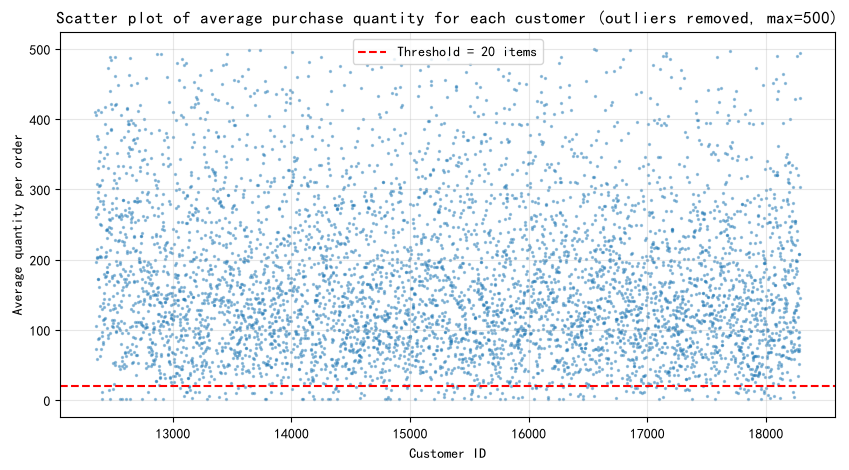

In [18]:
# Filter out large values greater than 500 to make density differences more obvious
upper_limit = 500
customer_filtered = customer_avg_qty[customer_avg_qty["avg_quantity_per_invoice"] <= upper_limit]
split_line = 20

plt.figure(figsize=(10, 5))
plt.scatter(
    customer_filtered["CustomerID"],
    customer_filtered["avg_quantity_per_invoice"],
    s=2,
    alpha=0.4
)
plt.axhline(y=split_line, color='red', linestyle='--', label=f'Threshold = 20 items')

plt.xlabel("Customer ID")
plt.ylabel("Average quantity per order")
plt.title("Scatter plot of average purchase quantity for each customer (outliers removed, max=500)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Show the proportion of wholesalers and individual customers among all customers:

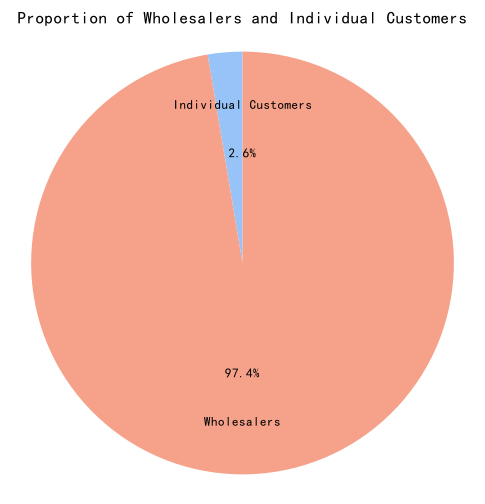

In [19]:
import os

split_line = 20
casual = customer_avg_qty[customer_avg_qty["avg_quantity_per_invoice"] <= split_line]
wholesale = customer_avg_qty[customer_avg_qty["avg_quantity_per_invoice"] > split_line]

sizes = [len(casual), len(wholesale)]
colors = ["#97c3f8", "#f6a28b"]

plt.figure(figsize=(6, 6))
wedges, _, autotexts = plt.pie(
    sizes,
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.55,
    textprops={"fontsize":9}
)
for t in autotexts:
    t.remove()

plt.text(0, 0.72, "Individual Customers", ha="center", va="bottom", fontsize=9)
plt.text(0, 0.55, "2.6%", ha="center", va="top", fontsize=9)
plt.text(0, -0.72, "Wholesalers", ha="center", va="top", fontsize=9)
plt.text(0, -0.55, "97.4%", ha="center", va="bottom", fontsize=9)
plt.title("Proportion of Wholesalers and Individual Customers")
plt.axis('equal')
os.makedirs("../images/outputs", exist_ok=True)
plt.show()

## RFM Analysis for Wholesalers
First, calculate the initial RFM values

In [20]:
# From the original cleaned order table, retrieve all orders belonging to wholesalers.
wholesale_customer = customer_avg_qty[customer_avg_qty["avg_quantity_per_invoice"] > 20]["CustomerID"]
wholesale_order = rfm_df[rfm_df["Customer ID"].isin(wholesale_customer)].copy()

# Calculate initial RFM values
wholesale_order["TotalPrice"] = wholesale_order["Quantity"] * wholesale_order["Price"]
snapshot_date = wholesale_order["InvoiceDate"].max()
rfm_wholesale = wholesale_order.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()
rfm_wholesale.head()

,Customer ID,Recency,Frequency,Monetary
0,12346.0,325,12,77556.46
1,12347.0,1,8,5633.32
2,12348.0,74,5,2019.40
3,12349.0,18,4,4428.69
4,12350.0,309,1,334.40


Assign stability labels to each wholesaler

In [21]:
# Sort orders and calculate gaps between consecutive invoices
wholesale_order = wholesale_order.sort_values(["Customer ID", "InvoiceDate"])
wholesale_order["prev_invoice_date"] = wholesale_order.groupby("Customer ID")["InvoiceDate"].shift(1)
wholesale_order["gap_days"] = (wholesale_order["InvoiceDate"] - wholesale_order["prev_invoice_date"]).dt.days

# Aggregate gap statistics for each customer
customer_gap_stats = wholesale_order.groupby("Customer ID")["gap_days"].agg(
    avg_gap = "mean",
    std_gap = "std"
).reset_index()
customer_gap_stats["cv"] = customer_gap_stats["std_gap"] / customer_gap_stats["avg_gap"]

# Count unique orders per customer
customer_order_count = wholesale_order.groupby("Customer ID")["Invoice"].nunique().reset_index()
customer_order_count.columns = ["Customer ID", "order_cnt"]
customer_gap_stats = customer_gap_stats.merge(customer_order_count, on="Customer ID", how="left")

# Define rhythm tagging function
def tag_rhythm(row):
    if row["order_cnt"] <= 2:
        return "Flexible"
    elif row["cv"] <= 1:
        return "Stable"
    else:
        return "Flexible"

customer_gap_stats["rhythm_type"] = customer_gap_stats.apply(tag_rhythm, axis=1)
customer_gap_stats.head()

,Customer ID,avg_gap,std_gap,cv,order_cnt,rhythm_type
0,12346.0,11.969697,40.413090,3.376283,12,Flexible
1,12347.0,1.583333,9.836360,6.212438,8,Flexible
2,12348.0,7.240000,28.617506,3.952694,5,Flexible
3,12349.0,3.270115,31.898349,9.754504,4,Flexible
4,12350.0,0.000000,0.000000,NaN,1,Flexible


Calculate the threshold of Recency, dichotomize R, F and M for final customer segmentation.

In [22]:
# Calculate unified Recency threshold, only from stable replenishment customers
stable_customer_gap = customer_gap_stats[customer_gap_stats["rhythm_type"] == "Stable"]
global_stable_avg_gap = stable_customer_gap["avg_gap"].mean()
print(f"Unified Recency threshold (from stable customers): {global_stable_avg_gap:.2f} days")

# Merge all metrics and rhythm label back to main RFM table
rfm_wholesale = rfm_wholesale.merge(
    customer_gap_stats[["Customer ID", "avg_gap","rhythm_type"]],
    on="Customer ID",
    how="left"
)

# Recency scoring: single unified threshold for all wholesalers
def r_rule(row):
    threshold = global_stable_avg_gap
    return "H" if row["Recency"] <= threshold else "L"

rfm_wholesale["R_score"] = rfm_wholesale.apply(r_rule, axis=1)

# Frequency and Monetary scored by median split
f_median = rfm_wholesale["Frequency"].median()
m_median = rfm_wholesale["Monetary"].median()
rfm_wholesale['F_score'] = rfm_wholesale['Frequency'].apply(lambda x: 'H' if x > f_median else 'L')
rfm_wholesale['M_score'] = rfm_wholesale['Monetary'].apply(lambda x: 'H' if x > m_median else 'L')

# Combine RFM labels
rfm_wholesale['RFM_segment'] = rfm_wholesale['R_score'] + rfm_wholesale['F_score'] + rfm_wholesale['M_score']
keep_cols = ["Customer ID","Recency","Frequency","Monetary","rhythm_type","RFM_segment"]
rfm_wholesale = rfm_wholesale[keep_cols]
rfm_wholesale.head()

Unified Recency threshold (from stable customers): 79.43 days


,Customer ID,Recency,Frequency,Monetary,rhythm_type,RFM_segment
0,12346.0,325,12,77556.46,Flexible,LHH
1,12347.0,1,8,5633.32,Flexible,HHH
2,12348.0,74,5,2019.40,Flexible,HHH
3,12349.0,18,4,4428.69,Flexible,HHH
4,12350.0,309,1,334.40,Flexible,LLL


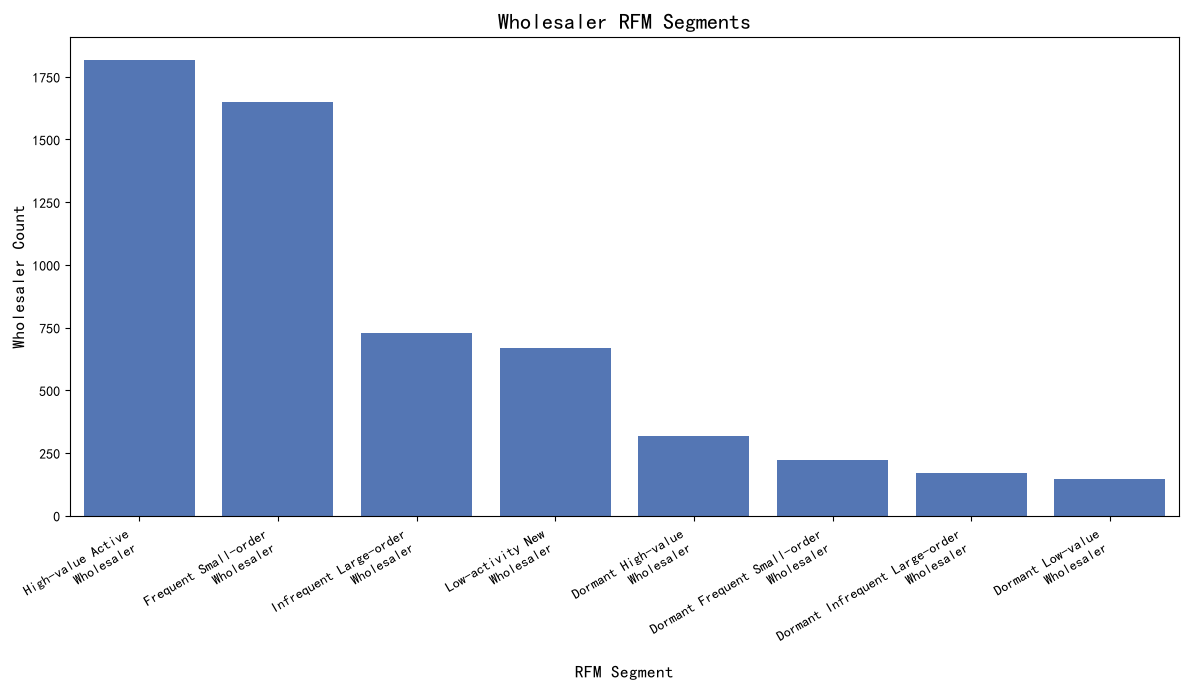

In [24]:
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

segment_labels = [
    "High-value Active\nWholesaler",
    "Frequent Small-order\nWholesaler",
    "Infrequent Large-order\nWholesaler",
    "Low-activity New\nWholesaler",
    "Dormant High-value\nWholesaler",
    "Dormant Frequent Small-order\nWholesaler",
    "Dormant Infrequent Large-order\nWholesaler",
    "Dormant Low-value\nWholesaler"
]

rfm_cnt = rfm_wholesale["RFM_segment"].value_counts().reindex(
    ["LLL", "HHH", "HLL", "LHH", "LLH", "HLH", "LHL", "HHL"]
).reset_index()
rfm_cnt.columns = ["RFM_segment", "customer_count"]
rfm_cnt["segment_name"] = segment_labels

plt.figure(figsize=(12, 7))
sns.barplot(data=rfm_cnt, x="segment_name", y="customer_count", color="#4472C4")
plt.title("Wholesaler RFM Segments", fontsize=16)
plt.xlabel("RFM Segment", fontsize=12)
plt.ylabel("Wholesaler Count", fontsize=12)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()